## Task 1: Setting the Baseline

### Imports

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, MultiTaskLassoCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor

### Auxiliary functions

In [36]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
def fixed_size_subframes(data):
    n = 257
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]


def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes


def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()
   
 
def create_features_and_targets(subframes):
    feature_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    target_labels = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']
    X_chunks = []
    y_chunks = []

    for df in subframes:        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)

    return X_chunks, y_chunks


def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions['Id'] = df_positions.index
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    df_positions.to_csv(path, index=False)
    
    
def save_model(model, name, input_df):
    print(type(model))
    initial_type = [('float_input', FloatTensorType([None, input_df.shape[1]]))]  
    # Convert the model to ONNX format
    onnx_model = convert_sklearn(model, initial_types=initial_type)
    # Save the ONNX model to a file
    with open(name, "wb") as f:
        f.write(onnx_model.SerializeToString())

## Task 1.1 Data Preparation and Validation Pipeline

### Load the dataset (without velocities)

In [37]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


### Dataframe should have the data grouped by scenarios

Split dataset into list of simulations

In [38]:
subframes = fixed_size_subframes(df)

Visualize trajectories

0


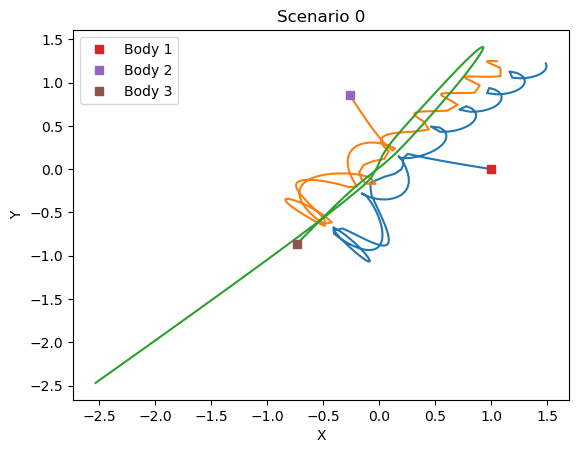

1


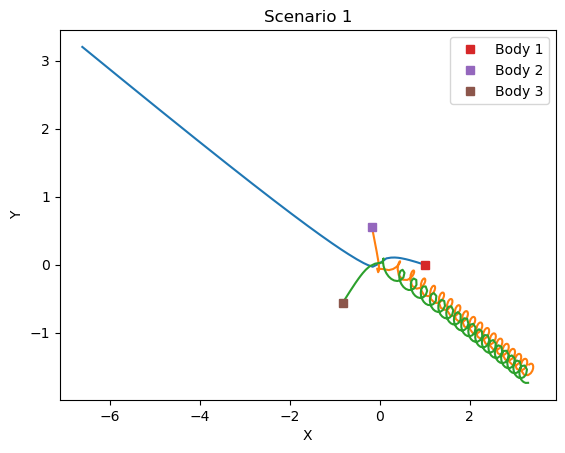

2


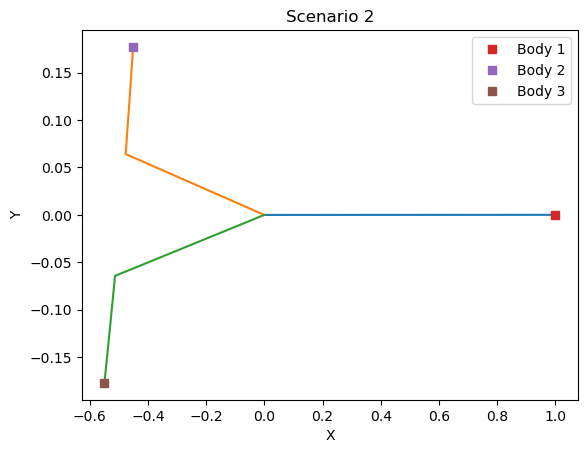

3


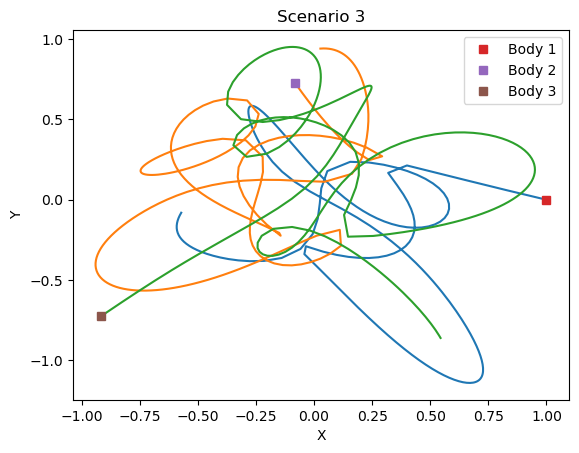

4


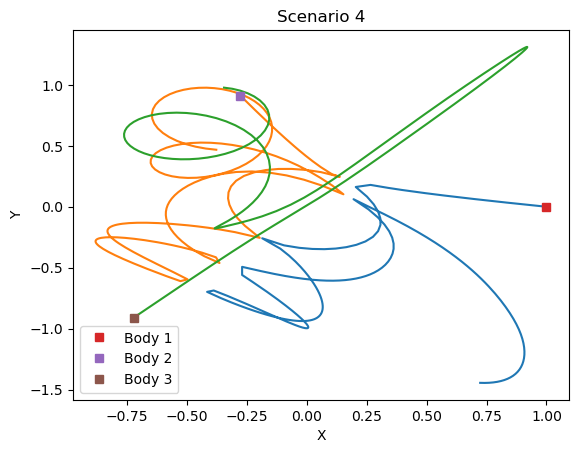

5


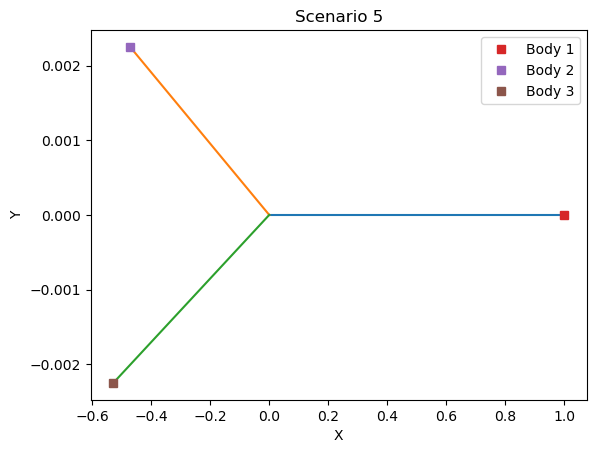

6


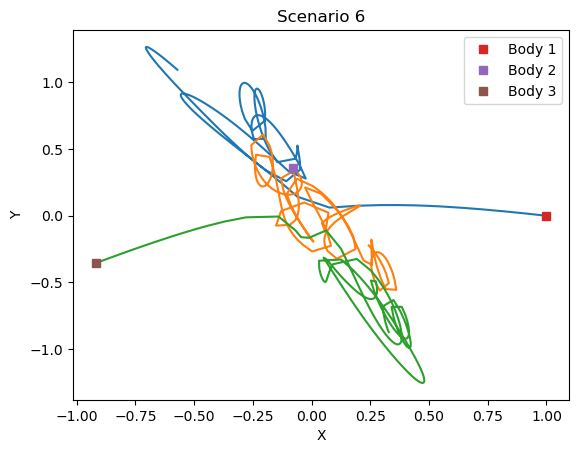

7


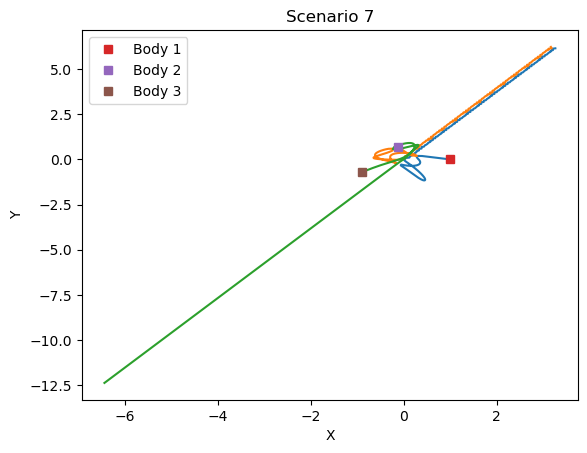

8


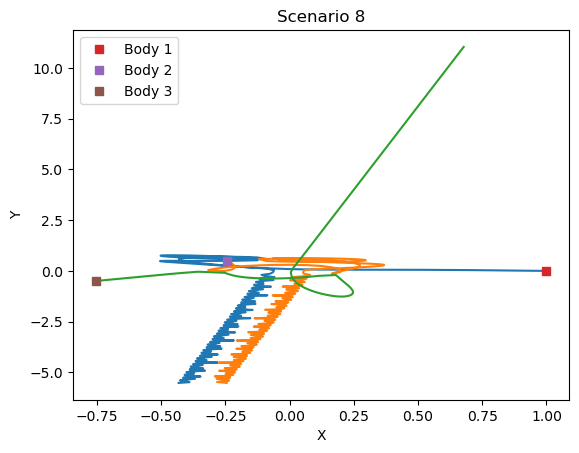

9


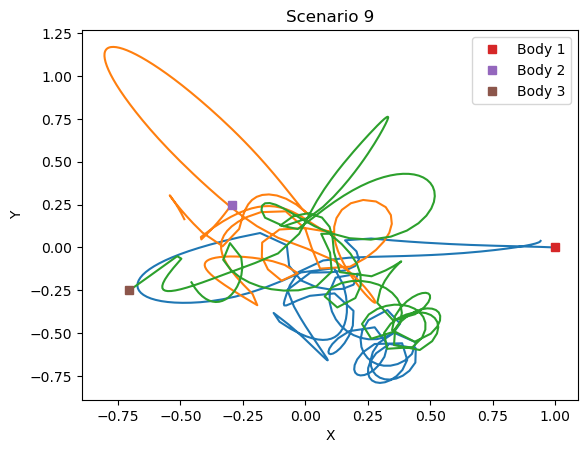

In [39]:
#ks = [2, 5, 284, 315, 317, 338, 4643] # some scenarios with collisions
ks = range(10)

for k in ks:
    subframe = subframes[k]
    first_row = subframe.iloc[0]
    
    print(k)
    plt.figure()

    plt.plot(subframe.x_1, subframe.y_1)
    plt.plot(subframe.x_2, subframe.y_2)
    plt.plot(subframe.x_3, subframe.y_3)

    plt.plot(first_row.x_1, first_row.y_1, 's', label='Body 1')
    plt.plot(first_row.x_2, first_row.y_2, 's', label='Body 2')
    plt.plot(first_row.x_3, first_row.y_3, 's', label='Body 3')
    
    plt.legend()
    plt.title(f'Scenario {k}')
    plt.xlabel('X')
    plt.ylabel('Y')
    
    plt.show()

Null rows are anomalies, we're removing them all

In [40]:
subframes = remove_useless_rows(subframes)

Create features and target matrices from the dataset

In [41]:
X_chunks, y_chunks = create_features_and_targets(subframes)

Split dataset into training (80%), validation (10%) and test (10%) sets.

In [42]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

# Concatenate the list of DataFrames into single DataFrames for X and y
X_train = pd.concat(X_train, axis=0)
y_train = pd.concat(y_train, axis=0)
X_dev = pd.concat(X_dev, axis=0)
y_dev = pd.concat(y_dev, axis=0)
X_test = pd.concat(X_test, axis=0)
y_test = pd.concat(y_test, axis=0)

## Task 1.2 Learn the baseline model

Linear regression model

In [43]:
linear_reg=make_pipeline(StandardScaler(),
                      LinearRegression())

linear_reg.fit(X_train, y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('linearregression', LinearRegression())])

Plot the y-y hat and present the RMSE in the validation set

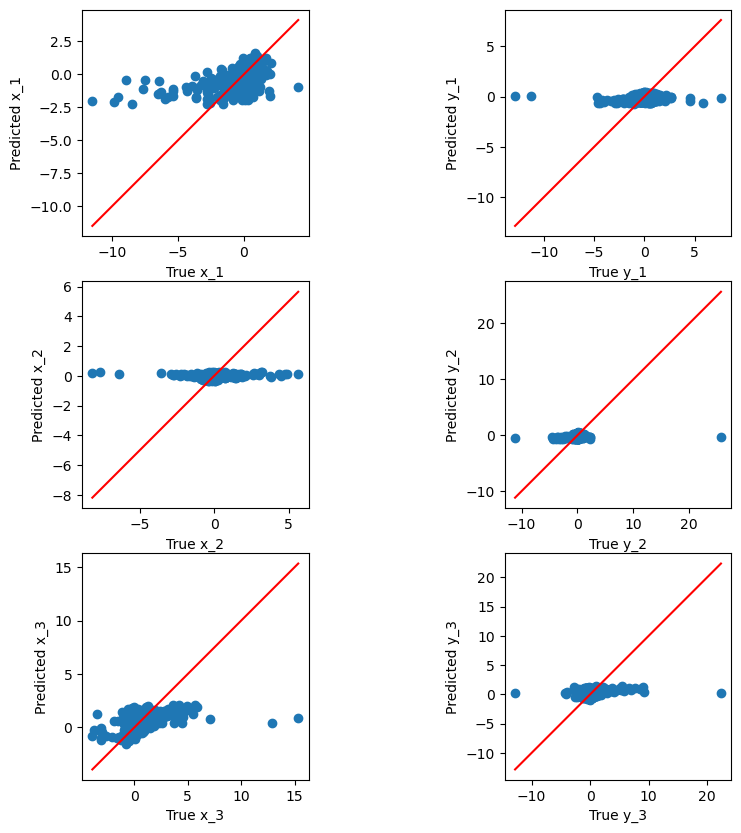

Validation RMSE: 1.3766263338318403


In [44]:
y_dev_pred = linear_reg.predict(X_dev)

plot_y_yhat(y_dev.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev, y_dev_pred)

print(f"Validation RMSE: {rmse}")

Plot y-y hat and RMSE on the test set

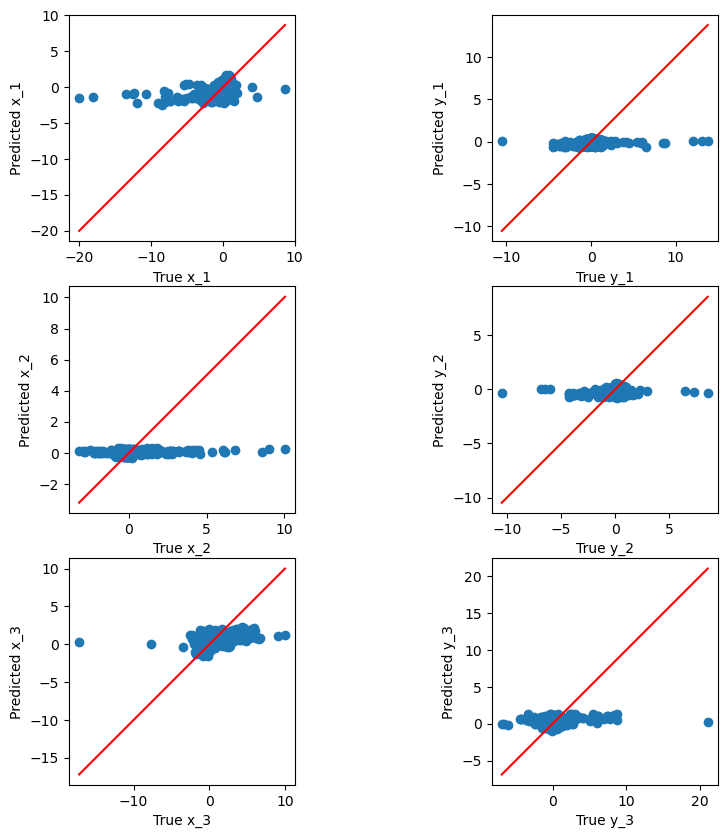

Test RMSE: 1.4524761254499114


In [45]:
y_test_pred = linear_reg.predict(X_test)

plot_y_yhat(y_test.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test, y_test_pred)

print(f"Test RMSE: {rmse}")

Save the prediction

In [46]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

y_baseline_pred = linear_reg.predict(X_kaggle_df)
save_predictions(y_baseline_pred, '../submissions/baseline-model.csv')

Save the model

In [47]:
save_model(linear_reg, "baseline_model.onnx", X_kaggle_df)

<class 'sklearn.pipeline.Pipeline'>
